In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

In [3]:
# Cari dataset dari direktori kerja notebook hingga root proyek.
data_path = next(
    (
        parent / "data" / "komdigi_hoaks.csv"
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "data" / "komdigi_hoaks.csv").is_file()
    ),
    None,
)
if data_path is None:
    raise FileNotFoundError("File data/komdigi_hoaks.csv tidak ditemukan dari direktori kerja saat ini.")

df = pd.read_csv(data_path)
required_columns = ["url", "title", "excerpt", "body_text", "topics"]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan pada dataset: {missing_columns}")

df = df.drop_duplicates(subset="url", keep="first").dropna(subset=["topics"]).copy()
text_columns = ["title", "excerpt", "body_text"]
df[text_columns] = df[text_columns].fillna("").astype(str)
df["article_text"] = (
    df[text_columns]
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
df = df.loc[df["article_text"].ne("")].reset_index(drop=True)

print(f"Lokasi dataset: {data_path.resolve()}")
print("Ukuran dataset setelah deduplikasi:", df.shape)
display(df[["topics", "title", "excerpt"]].head())

Lokasi dataset: D:\Kuliah\Kelas\Semester 5\Pembelajaran Mesin\TUGAS\PRAKTIKUM\data\komdigi_hoaks.csv
Ukuran dataset setelah deduplikasi: (4162, 14)


,topics,title,excerpt
0,Hoaks,[HOAKS] Tautan Pencairan BSU September 2026 Se...,Kepala Biro Humas Kementerian Ketenagakerjaan ...
1,Hoaks,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...,El Nino merupakan fenomena alam yang terjadi a...
2,Hoaks,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,Maltodekstrin merupakan bahan tambahan pangan ...
3,Hoaks,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...,
4,Hoaks,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...,


In [4]:
# Prediksi kategori topics dari gabungan teks artikel.
# topics adalah kategori konten, bukan label klaim benar atau salah.
X = df["article_text"]
y = df["topics"]
labels = sorted(y.unique())
print("Jumlah kelas:", len(labels))
print("Distribusi kelas:")
display(y.value_counts().rename_axis("topics").to_frame("jumlah"))

Jumlah kelas: 6
Distribusi kelas:


,jumlah
topics,
Hoaks,3524
Penipuan,286
Pejabat Publik,135
Masyarakat Digital,102
Program/Kebijakan,59
Kesehatan,56


In [5]:
# Bandingkan kernel Linear, Polynomial, dan RBF pada dua rasio split.
split_ratios = {"70:30": 0.30, "80:20": 0.20}
kernels = ["linear", "poly", "rbf"]
results = []

for split_name, test_size in split_ratios.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y,
    )

    for kernel_name in kernels:
        model = Pipeline(
            [
                (
                    "tfidf",
                    TfidfVectorizer(
                        max_features=3000,
                        min_df=2,
                        ngram_range=(1, 2),
                        sublinear_tf=True,
                    ),
                ),
                (
                    "svc",
                    SVC(
                        kernel=kernel_name,
                        degree=2,
                        class_weight="balanced",
                        random_state=42,
                    ),
                ),
            ]
        )
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        results.append(
            {
                "Split": split_name,
                "Kernel": kernel_name,
                "Accuracy": accuracy_score(y_test, y_pred),
                "Macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
            }
        )
        print(
            f"Split {split_name} | Kernel {kernel_name} | "
            f"Accuracy: {results[-1]['Accuracy']:.4f} | "
            f"Macro F1: {results[-1]['Macro F1']:.4f}"
        )

Split 70:30 | Kernel linear | Accuracy: 0.7398 | Macro F1: 0.4159
Split 70:30 | Kernel poly | Accuracy: 0.8118 | Macro F1: 0.3153
Split 70:30 | Kernel rbf | Accuracy: 0.7750 | Macro F1: 0.3326
Split 80:20 | Kernel linear | Accuracy: 0.7395 | Macro F1: 0.3911
Split 80:20 | Kernel poly | Accuracy: 0.8127 | Macro F1: 0.3422
Split 80:20 | Kernel rbf | Accuracy: 0.7755 | Macro F1: 0.3254


In [6]:
# Ringkas perbandingan kernel dan rasio pembagian data.
results_df = pd.DataFrame(results)
results_df["Accuracy (%)"] = (results_df["Accuracy"] * 100).round(2)
results_df["Macro F1"] = results_df["Macro F1"].round(4)
display(
    results_df.sort_values(["Split", "Macro F1"], ascending=[True, False])[
        ["Split", "Kernel", "Accuracy (%)", "Macro F1"]
    ].reset_index(drop=True)
)

,Split,Kernel,Accuracy (%),Macro F1
0,70:30,linear,73.98,0.4159
1,70:30,rbf,77.50,0.3326
2,70:30,poly,81.18,0.3153
3,80:20,linear,73.95,0.3911
4,80:20,poly,81.27,0.3422
5,80:20,rbf,77.55,0.3254


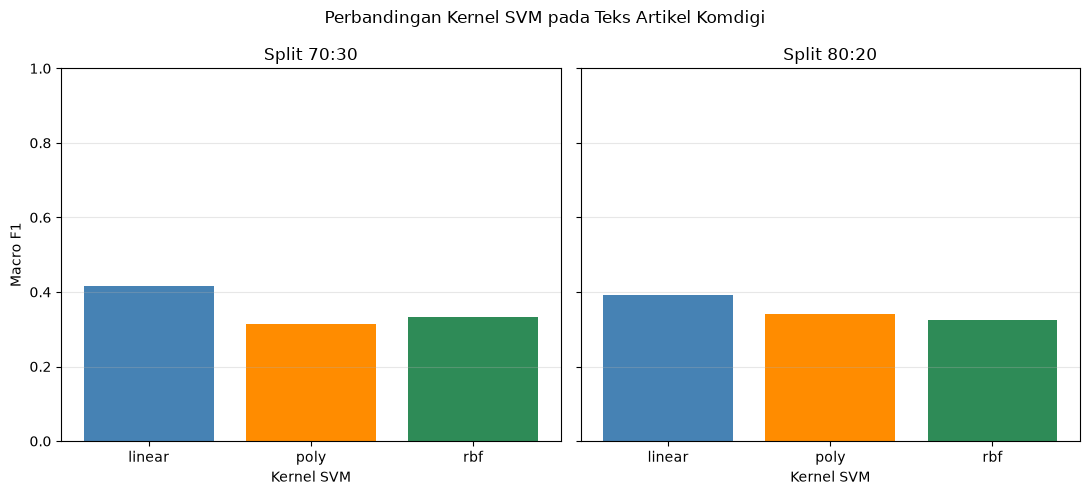

In [7]:
# Bandingkan Macro F1 untuk setiap kernel dan rasio split.
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, (split_name, _) in zip(axes, split_ratios.items()):
    subset = results_df[results_df["Split"] == split_name]
    ax.bar(subset["Kernel"], subset["Macro F1"], color=["steelblue", "darkorange", "seagreen"])
    ax.set_title(f"Split {split_name}")
    ax.set_xlabel("Kernel SVM")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Macro F1")
fig.suptitle("Perbandingan Kernel SVM pada Teks Artikel Komdigi")
fig.tight_layout()
plt.show()

In [8]:
# Siapkan satu holdout 80:20 untuk membandingkan baseline dan model tuned.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

# TF-IDF diletakkan di dalam pipeline agar setiap fold hanya belajar vocabulary
# dari bagian training-nya dan tidak terjadi data leakage.
def make_svc_pipeline():
    return Pipeline(
        [
            (
                "tfidf",
                TfidfVectorizer(
                    max_features=3000,
                    min_df=2,
                    ngram_range=(1, 2),
                    sublinear_tf=True,
                ),
            ),
            ("svc", SVC(class_weight="balanced", random_state=42)),
        ]
    )

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 3329
Jumlah data testing: 833


In [9]:
# Baseline SVM RBF dengan parameter default.
baseline_model = make_svc_pipeline()
baseline_model.set_params(svc__kernel="rbf")
baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_macro_f1 = f1_score(y_test, baseline_pred, average="macro", zero_division=0)

print(f"Baseline accuracy: {baseline_accuracy:.4f}")
print(f"Baseline macro F1: {baseline_macro_f1:.4f}")

Baseline accuracy: 0.7755
Baseline macro F1: 0.3254


In [10]:
# Tuning C dan gamma pada SVM RBF dengan validasi silang terstratifikasi.
# Data testing tidak digunakan dalam pemilihan parameter.
pipeline = make_svc_pipeline()
param_grid = {
    "svc__kernel": ["linear", "rbf"],
    "svc__C": [0.1, 1, 10],
    "svc__gamma": ["scale", 0.1],
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    refit=True,
)
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print(f"Best CV macro F1: {grid_search.best_score_:.4f}")

Best parameters: {'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Best CV macro F1: 0.4118


In [11]:
# Evaluasi model terbaik pada holdout test yang sama dengan baseline.
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
tuned_accuracy = accuracy_score(y_test, y_pred)
tuned_macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

print(f"Test accuracy: {tuned_accuracy:.4f}")
print(f"Test macro F1: {tuned_macro_f1:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, labels=labels, target_names=labels, zero_division=0))

Test accuracy: 0.7395
Test macro F1: 0.3911

Classification report:
                    precision    recall  f1-score   support

             Hoaks       0.93      0.76      0.84       705
         Kesehatan       0.17      0.27      0.21        11
Masyarakat Digital       0.25      0.33      0.29        21
    Pejabat Publik       0.28      0.78      0.42        27
          Penipuan       0.36      0.79      0.49        57
 Program/Kebijakan       0.14      0.08      0.11        12

          accuracy                           0.74       833
         macro avg       0.36      0.50      0.39       833
      weighted avg       0.83      0.74      0.77       833



In [12]:
# Bandingkan baseline dan hasil tuning pada data uji yang sama.
comparison_df = pd.DataFrame(
    {
        "Model": ["SVM RBF Baseline", "SVM Tuned"],
        "Kernel": ["rbf", grid_search.best_params_["svc__kernel"]],
        "Accuracy (%)": [baseline_accuracy * 100, tuned_accuracy * 100],
        "Macro F1": [baseline_macro_f1, tuned_macro_f1],
    }
)
comparison_df["Accuracy (%)"] = comparison_df["Accuracy (%)"].round(2)
comparison_df["Macro F1"] = comparison_df["Macro F1"].round(4)
display(comparison_df)

,Model,Kernel,Accuracy (%),Macro F1
0,SVM RBF Baseline,rbf,77.55,0.3254
1,SVM Tuned,linear,73.95,0.3911


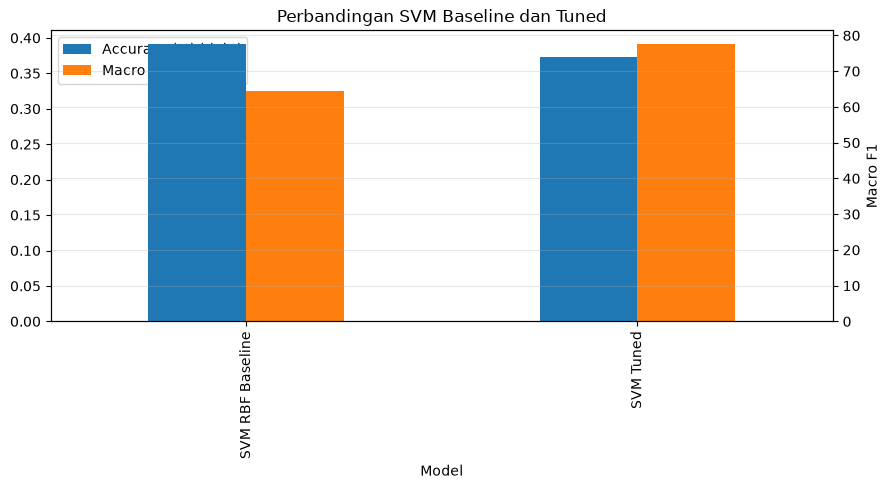

In [13]:
# Plot kedua metrik; macro F1 memberi bobot setara pada setiap kelas.
comparison_df.set_index("Model")[["Accuracy (%)", "Macro F1"]].plot(
    kind="bar",
    figsize=(9, 5),
    secondary_y="Accuracy (%)",
)
plt.title("Perbandingan SVM Baseline dan Tuned")
plt.xlabel("Model")
plt.ylabel("Macro F1")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Kesimpulan

Notebook ini menggunakan `komdigi_hoaks.csv` untuk mengklasifikasikan kategori `topics` dari teks gabungan judul, ringkasan, dan isi artikel. Kategori tersebut merupakan topik konten, bukan penilaian benar atau salahnya klaim.

Pertama, kernel SVM Linear, Polynomial, dan RBF dibandingkan pada rasio split 70:30 dan 80:20. Hasil akurasi dan Macro F1 dicetak dalam tabel dan grafik. Kedua, baseline SVM RBF dibandingkan dengan SVM yang parameter kernel, `C`, dan `gamma`-nya dipilih melalui validasi silang pada data training. Data uji final tidak dipakai dalam tuning.

Gunakan Macro F1 bersama akurasi dan laporan per kelas saat menilai hasil, karena jumlah artikel setiap topik tidak seimbang. Hasil akhir pada data uji dan parameter terbaik ditampilkan secara langsung oleh sel notebook.